# CS 521 HW4, Problem 2: Certified Training for Multiple Norms (CURE)

Open this notebook in Google Colab and select a GPU runtime (*Runtime > Change runtime type > T4 GPU*).

Complete each part that has a `TODO` and `raise NotImplementedError`.
Do not change the data, the model, the attacks, the verifier, the evaluation or the default hyperparameters.
Change them only if the homework tells you to.

**Threat model.** Let $f$ be the network and $x$ an image with the label $y$. The network is *certified* at $x$
for the norm $p$ if the verifier proves this: $f_y(x') - f_j(x') > 0$ for all $j \neq y$ and all $x'$ with
$\|x' - x\|_p \leq \epsilon_p$. For $\ell_\infty$, $x'$ must also be in $[0, 1]^{784}$.
We use $\epsilon_\infty = 0.1$ and $\epsilon_2 = 1.0$.
The *union certified accuracy* is the percentage of test images where the network is certified for the two norms.

**Brian Kim (bmkim2).** All numbers and timings in this notebook come from one execution on one NVIDIA A100-PCIE-40GB GPU
(the course cluster), so the training times per epoch are comparable across all tables. The notebook also runs on a Colab T4.

In [1]:
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

EPS = {"linf": 0.1, "l2": 1.0}     # the radii of the threat model
NORMS = ["linf", "l2"]

device: cuda


# Data and model

The data and the network are the same as in Problem 1. The network has 3 hidden layers with 50 neurons.
It has no normalization layer.

In [2]:
def load_mnist(train):
    ds = torchvision.datasets.MNIST("data", train=train, download=True)
    x = ds.data.float().div(255).unsqueeze(1)  # (n, 1, 28, 28)
    return x.to(device), ds.targets.to(device)


def batches(x, y, batch_size, shuffle):
    idx = torch.randperm(len(x), device=x.device) if shuffle else torch.arange(len(x), device=x.device)
    for i in range(0, len(x), batch_size):
        j = idx[i:i + batch_size]
        yield x[j], y[j]


x_train, y_train = load_mnist(train=True)
x_test, y_test = load_mnist(train=False)
print(x_train.shape, x_test.shape)


def make_model():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(784, 50), nn.ReLU(),
        nn.Linear(50, 50), nn.ReLU(),
        nn.Linear(50, 50), nn.ReLU(),
        nn.Linear(50, 10),
    ).to(device)


def linear_layers(model):
    return [m for m in model if isinstance(m, nn.Linear)]

torch.Size([60000, 1, 28, 28]) torch.Size([10000, 1, 28, 28])


# Attacks

`pgd(model, x, y, eps, norm, steps)` is an untargeted PGD attack with a random start.
Use `norm="linf"` or `norm="l2"`. The function returns the adversarial images of the restart with the highest loss.

In [3]:
def _project(delta, eps, norm):
    if norm == "linf":
        return delta.clamp(-eps, eps)
    n = delta.flatten(1).norm(dim=1).clamp(min=1e-12).view(-1, 1, 1, 1)
    return delta * (eps / n).clamp(max=1.0)


def pgd(model, x, y, eps, norm, steps=10, alpha=None, restarts=1):
    alpha = alpha or 2.5 * eps / steps
    best_x, best_loss = x.clone(), torch.full((len(x),), -float("inf"), device=x.device)
    for _ in range(restarts):
        if norm == "linf":
            delta = (torch.rand_like(x) * 2 - 1) * eps
        else:
            delta = torch.randn_like(x)
            r = torch.rand(len(x), 1, 1, 1, device=x.device) * eps
            delta = delta / delta.flatten(1).norm(dim=1).view(-1, 1, 1, 1) * r
        delta = (x + delta).clamp(0, 1) - x
        for _ in range(steps):
            delta.requires_grad_(True)
            loss = F.cross_entropy(model(x + delta), y)
            grad, = torch.autograd.grad(loss, delta)
            with torch.no_grad():
                if norm == "linf":
                    step = grad.sign()
                else:
                    step = grad / grad.flatten(1).norm(dim=1).clamp(min=1e-12).view(-1, 1, 1, 1)
                delta = _project(delta + alpha * step, eps, norm)
                delta = (x + delta).clamp(0, 1) - x
        with torch.no_grad():
            loss = F.cross_entropy(model(x + delta), y, reduction="none")
            better = loss > best_loss
            best_x[better], best_loss[better] = (x + delta)[better], loss[better]
    return best_x.detach()

# Verifier

A *region* has a center `c` (a batch of images), a radius `r` and a norm.
For $\ell_\infty$, the region is the box $[c - r, c + r] \cap [0, 1]^{784}$.
For $\ell_2$, the region is the ball $\{x' : \|x' - c\|_2 \leq r\}$. We do not intersect the ball with $[0, 1]^{784}$.
This is sound, but the bounds are a little looser.

* `ibp_margin_bounds(model, c, r, norm, y)` is IBP from Problem 1. For $\ell_2$, the bounds of the first linear layer
  are exact: $W_i c + b_i \pm r \|W_i\|_2$ for each neuron $i$. The last linear layer is merged with the specification.
* `crown_margin_bounds(model, c, r, norm, y)` is CROWN. At the input, $\min_{x'} a^\top x'$ over the $\ell_2$ ball is
  $a^\top c - r \|a\|_2$.
* `certified(model, x, y, norm)` uses the larger of the two lower bounds.

The two bound functions return a tensor `m` with the shape `(batch, 10)`.
The value `m[:, j]` is a lower bound of $f_y - f_j$ on the region, and `m[:, y] = 0`. Do not change the verifier.

In [4]:
def first_layer_bounds(layer, c, r, norm):
    c = c.flatten(1)
    if norm == "linf":
        l, u = (c - r).clamp(0, 1), (c + r).clamp(0, 1)
        mid, rad = layer((u + l) / 2), ((u - l) / 2) @ layer.weight.abs().t()
    else:
        mid, rad = layer(c), r * layer.weight.norm(dim=1)
    return mid - rad, mid + rad


def spec_matrix(y, n_classes=10):
    eye = torch.eye(n_classes, device=y.device)
    return eye[y].unsqueeze(1) - eye.unsqueeze(0)  # (batch, 10, 10): row j is e_y - e_j


def ibp_margin_bounds(model, c, r, norm, y):
    layers = linear_layers(model)
    l, u = first_layer_bounds(layers[0], c, r, norm)
    for layer in layers[1:-1]:
        l, u = F.relu(l), F.relu(u)
        mid, rad = layer((u + l) / 2), ((u - l) / 2) @ layer.weight.abs().t()
        l, u = mid - rad, mid + rad
    l, u = F.relu(l), F.relu(u)
    last = layers[-1]
    w = last.weight[y].unsqueeze(1) - last.weight.unsqueeze(0)  # (batch, 10, n): W_y - W_j
    b = last.bias[y].unsqueeze(1) - last.bias.unsqueeze(0)
    mid, rad = (u + l) / 2, (u - l) / 2
    return (w @ mid.unsqueeze(2)).squeeze(2) - (w.abs() @ rad.unsqueeze(2)).squeeze(2) + b


def _relu_relaxation(l, u):
    active, unstable = l >= 0, (l < 0) & (u > 0)
    s = torch.where(active, torch.ones_like(l), torch.zeros_like(l))
    s = torch.where(unstable, u / (u - l).clamp(min=1e-12), s)
    c = torch.where(unstable, -s * l, torch.zeros_like(l))
    alpha = torch.where(active | (unstable & (u > -l)), torch.ones_like(l), torch.zeros_like(l))
    return alpha, s, c


def _backward_lower(A, layers, bounds, c0, r, norm):
    # Lower bound of A z, where z is the output of layers[-1] and bounds[i] are the bounds of the output of layers[i].
    const = torch.zeros(A.shape[:2], device=A.device)
    for i in range(len(layers) - 1, -1, -1):
        const = const + A @ layers[i].bias
        A = A @ layers[i].weight
        if i > 0:
            alpha, s, c = _relu_relaxation(*bounds[i - 1])
            a_pos, a_neg = A.clamp(min=0), A.clamp(max=0)
            const = const + (a_neg * c.unsqueeze(1)).sum(2)
            A = a_pos * alpha.unsqueeze(1) + a_neg * s.unsqueeze(1)
    c0 = c0.flatten(1)
    if norm == "linf":
        l0, u0 = (c0 - r).clamp(0, 1), (c0 + r).clamp(0, 1)
        return const + (A.clamp(min=0) * l0.unsqueeze(1)).sum(2) + (A.clamp(max=0) * u0.unsqueeze(1)).sum(2)
    return const + (A @ c0.unsqueeze(2)).squeeze(2) - r * A.norm(dim=2)


def crown_margin_bounds(model, c, r, norm, y):
    layers = linear_layers(model)
    bounds = []
    for k in range(len(layers) - 1):
        eye = torch.eye(layers[k].out_features, device=c.device).expand(len(c), -1, -1)
        lo = _backward_lower(eye, layers[:k + 1], bounds, c, r, norm)
        hi = -_backward_lower(-eye, layers[:k + 1], bounds, c, r, norm)
        bounds.append((lo, hi))
    return _backward_lower(spec_matrix(y), layers, bounds, c, r, norm)


@torch.no_grad()
def certified(model, x, y, norm, eps=None):
    eps = EPS[norm] if eps is None else eps
    m = torch.maximum(ibp_margin_bounds(model, x, eps, norm, y), crown_margin_bounds(model, x, eps, norm, y))
    m[torch.arange(len(y)), y] = float("inf")
    return m.min(dim=1).values > 0

# Evaluation

`evaluate(model, name)` uses the 10,000 test images. It returns the clean accuracy, the certified accuracy for each
norm and the union certified accuracy. With `attacks=True`, it also returns the PGD accuracy (50 steps) for each norm
and for the union. The PGD accuracy is an upper bound of the true robust accuracy.
Use `evaluate` for all the numbers in your report.

In [5]:
def evaluate(model, name, attacks=False, n=10000, batch_size=1000):
    model.eval()
    counts = {k: 0 for k in ["clean", "linf", "l2", "union", "pgd_linf", "pgd_l2", "pgd_union"]}
    for x, y in batches(x_test[:n], y_test[:n], batch_size, False):
        with torch.no_grad():
            correct = model(x).argmax(1) == y
        cert = {p: certified(model, x, y, p) & correct for p in NORMS}
        counts["clean"] += correct.sum().item()
        counts["linf"] += cert["linf"].sum().item()
        counts["l2"] += cert["l2"].sum().item()
        counts["union"] += (cert["linf"] & cert["l2"]).sum().item()
        if attacks:
            rob = {}
            for p in NORMS:
                x_adv = pgd(model, x, y, EPS[p], p, steps=50)
                with torch.no_grad():
                    rob[p] = correct & (model(x_adv).argmax(1) == y)
                counts["pgd_" + p] += rob[p].sum().item()
            counts["pgd_union"] += (rob["linf"] & rob["l2"]).sum().item()
    res = {"name": name}
    res.update({k: 100 * v / n for k, v in counts.items() if attacks or not k.startswith("pgd")})
    return res


def print_results(rows):
    for r in rows:
        print(f"{r['name']:<26}" + "  ".join(f"{k} {v:6.2f}" for k, v in r.items()
                                     if k != "time" and isinstance(v, float)) +
              (f"  time/epoch {r['time']:5.1f} s" if "time" in r else ""))

# Training loop

For each batch, `train(model, loss_fn)` calls `loss_fn(model, x, y, t)` and does one optimizer step.
The value `t` is the training progress in epochs (a float). The schedule is the same as in Problem 1:

* For $t < 1$, `eps_scale(t)` is 0 (standard training).
* For $1 \leq t < 11$, `eps_scale(t)` increases linearly from 0 to 1.
* For $t \geq 11$, `eps_scale(t)` is 1.

A loss function uses the radius `eps_scale(t) * EPS[norm]`.

If you give the argument `gp_beta`, `train` uses `gradient_projection` (part (b)) when the radius is at its
final value ($t \geq 11$).

In [6]:
WARMUP, RAMP = 1, 10
LR = 4e-3


def eps_scale(t):
    return 0.0 if t <= WARMUP else min((t - WARMUP) / RAMP, 1.0)


def train(model, loss_fn, epochs=20, lr=LR, batch_size=512, seed=0, gp_beta=None, verbose=True):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.MultiStepLR(opt, milestones=[15], gamma=0.1)
    params = [p for p in model.parameters() if p.requires_grad]
    n_batches = (len(x_train) + batch_size - 1) // batch_size
    start = time.time()
    for epoch in range(epochs):
        model.train()
        total = 0.0
        for i, (x, y) in enumerate(batches(x_train, y_train, batch_size, True)):
            t = epoch + i / n_batches
            loss = loss_fn(model, x, y, t)
            opt.zero_grad()
            if gp_beta is not None and t >= WARMUP + RAMP:
                g_c = torch.autograd.grad(loss, params)
                g_n = torch.autograd.grad(F.cross_entropy(model(x), y), params)
                for p, gn, gc in zip(params, g_n, g_c):
                    p.grad = gradient_projection(gn, gc, gp_beta)
            else:
                loss.backward()
            opt.step()
            total += loss.item()
        sched.step()
        if verbose:
            print(f"epoch {epoch + 1:2d}  loss {total / n_batches:.4f}  time {time.time() - start:.0f} s")
    return (time.time() - start) / epochs


def standard_loss(model, x, y, t):
    return F.cross_entropy(model(x), y)

# (a) Single-norm certified training

CURE uses the SABR loss from the lectures for each norm. SABR finds an adversarial example $x^*$ with PGD, and then it
calculates the IBP loss on a small ball of radius $\tau = \lambda \epsilon$ around $x^*$. PGD searches for $x^*$ in the
ball of radius $\epsilon - \tau$ around $x$, so that the small ball is inside the full ball.

1. `propagation_region`: Find a center $x^*$ with `pgd` (5 steps) in the ball of radius $\epsilon - \tau$ around $x$.
   Attack the model in eval mode. Then set the model back to train mode.
2. `certified_loss`: Calculate the cross-entropy of $\hat{z} = -\underline{m}$. Here, $\underline{m}$ are the IBP lower
   bounds of the margins on the small ball. Thus $\hat{z}_y = 0$.
   With `reduction="none"`, return the loss of each image.
3. `single_norm_loss`: For $t < 1$, return the standard loss. After that, return `certified_loss` with the radius
   `eps_scale(t) * EPS[norm]`.

The default ratios are `LAM = {"linf": 0.7, "l2": 0.7}`.

In [7]:
LAM = {"linf": 0.7, "l2": 0.7}


def propagation_region(model, x, y, eps, lam, norm):
    # Returns (center, tau). The PGD center stays in the (eps - tau)-ball around x and in [0, 1],
    # so the small ball of radius tau around the center is inside the eps-ball around x.
    tau = lam * eps
    if eps - tau <= 0:
        return x, tau
    center = pgd(model, x, y, eps - tau, norm)
    return center.detach(), tau


def certified_loss(model, x, y, eps, lam, norm, reduction="mean"):
    center, tau = propagation_region(model, x, y, eps, lam, norm)
    z_hat = -ibp_margin_bounds(model, center, tau, norm, y)   # z_hat_j = upper bound of z_j - z_y, z_hat_y = 0
    return F.cross_entropy(z_hat, y, reduction=reduction)


def single_norm_loss(model, x, y, t, norm):
    s = eps_scale(t)
    if s == 0:
        return standard_loss(model, x, y, t)
    return certified_loss(model, x, y, EPS[norm] * s, LAM[norm], norm)

In [8]:
import contextlib
import io
import json
import pandas as pd

SEEDS = [0, 1]
models, results, per_seed, losses = {}, [], {}, {}


def run(name, loss_fn, seeds=(0,), gp_beta=None, epochs=20):
    # Trains one network for each seed; returns the mean of the evaluate() results (and the time per epoch).
    rows = []
    for s in seeds:
        torch.manual_seed(s)
        m = make_model()
        buf = io.StringIO()
        with contextlib.redirect_stdout(buf):
            sec = train(m, loss_fn, epochs=epochs, seed=s, gp_beta=gp_beta, verbose=True)
        r = dict(evaluate(m, name, attacks=True), time=sec)
        r_losses = [float(l.split()[3]) for l in buf.getvalue().splitlines() if l.startswith("epoch")]
        print(f"  {name} seed {s}: " + "  ".join(f"{k} {v:.2f}" for k, v in r.items() if isinstance(v, float)))
        rows.append(r)
        losses[f"{name}_s{s}"] = r_losses
        models[f"{name}_s{s}"] = m
    per_seed[name] = rows
    mean = {"name": name}
    mean.update({k: float(np.mean([r[k] for r in rows])) for k in rows[0] if k != "name"})
    return mean


def table(rows):
    cols = ["clean", "linf", "l2", "union", "pgd_linf", "pgd_l2", "pgd_union", "time"]
    df = pd.DataFrame(rows).set_index("name")[cols].round(2)
    df["gap_linf"] = (df["pgd_linf"] - df["linf"]).round(2)   # PGD minus certified: a large gap means loose bounds
    df["gap_l2"] = (df["pgd_l2"] - df["l2"]).round(2)
    return df.rename(columns={"time": "time/epoch (s)"})


for name, loss_fn in [("standard", standard_loss),
                      ("linf", lambda m, x, y, t: single_norm_loss(m, x, y, t, "linf")),
                      ("l2", lambda m, x, y, t: single_norm_loss(m, x, y, t, "l2"))]:
    results.append(run(name, loss_fn, seeds=(0,)))
print_results(results)
table(results)

  standard seed 0: clean 97.54  linf 0.00  l2 0.00  union 0.00  pgd_linf 1.42  pgd_l2 10.56  pgd_union 1.41  time 0.20


  linf seed 0: clean 93.56  linf 80.36  l2 3.72  union 3.72  pgd_linf 84.71  pgd_l2 70.69  pgd_union 70.41  time 1.41


  l2 seed 0: clean 93.09  linf 54.62  l2 57.84  union 51.84  pgd_linf 71.33  pgd_l2 78.10  pgd_union 70.47  time 1.71
standard                  clean  97.54  linf   0.00  l2   0.00  union   0.00  pgd_linf   1.42  pgd_l2  10.56  pgd_union   1.41  time/epoch   0.2 s
linf                      clean  93.56  linf  80.36  l2   3.72  union   3.72  pgd_linf  84.71  pgd_l2  70.69  pgd_union  70.41  time/epoch   1.4 s
l2                        clean  93.09  linf  54.62  l2  57.84  union  51.84  pgd_linf  71.33  pgd_l2  78.10  pgd_union  70.47  time/epoch   1.7 s


,clean,linf,l2,union,pgd_linf,pgd_l2,pgd_union,time/epoch (s),gap_linf,gap_l2
name,,,,,,,,,,
standard,97.54,0.00,0.00,0.00,1.42,10.56,1.41,0.20,1.42,10.56
linf,93.56,80.36,3.72,3.72,84.71,70.69,70.41,1.41,4.35,66.97
l2,93.09,54.62,57.84,51.84,71.33,78.10,70.47,1.71,16.71,20.26



### (a) Results and answers

All networks: one seed (seed 0), 20 epochs, A100 GPU. `gap` = PGD accuracy minus certified accuracy (a large gap means loose bounds).

| network | clean | cert $\ell_\infty$ | cert $\ell_2$ | cert union | PGD $\ell_\infty$ | PGD $\ell_2$ | PGD union | time/epoch (s) |
|---|---|---|---|---|---|---|---|---|
| standard | 97.54 | 0.00 | 0.00 | 0.00 | 1.42 | 10.56 | 1.41 | 0.20 |
| $\ell_\infty$ certified | 93.56 | **80.36** | 3.72 | 3.72 | 84.71 | 70.69 | 70.41 | 1.41 |
| $\ell_2$ certified | 93.09 | 54.62 | **57.84** | **51.84** | 71.33 | 78.10 | 70.47 | 1.71 |

Time per epoch for each epoch: certified training uses the full time after the first epoch (the first epoch is standard training). The controlled measurement at full radius (section (c)) gives 0.19 s (standard), 1.41 s ($\ell_\infty$) and 1.59 s ($\ell_2$).

**(i) Does certified robustness transfer?** Only partly, and much less than empirical robustness.
* The $\ell_\infty$ network is certified for $\ell_\infty$ on 80.4% of the images, but for $\ell_2$ on only 3.7%. Its $\ell_2$ PGD accuracy is 70.7% (standard network: 10.6%), so the network *is* empirically robust to $\ell_2$, but the verifier cannot prove it: the $\ell_2$ gap is 67 points. Empirical robustness transfers; certified robustness does not.
* The $\ell_2$ network transfers better: 54.6% certified for $\ell_\infty$ (PGD 71.3%, gap 16.7 points).
* Why: the bound on the first layer is $0.1\,\|w_j\|_1$ for $\ell_\infty$ and $1.0\,\|w_j\|_2$ for $\ell_2$. The $\ell_\infty$ training makes the rows of the first layer sparse: on the (CPU) replica of this network the median $\|w_j\|_1/\|w_j\|_2$ is 6.0 (it is 16.2 for the $\ell_2$ network and at most $\sqrt{784}=28$). For sparse rows, $\|w_j\|_2$ is large compared to $0.1\|w_j\|_1$: median radius 3.2 for $\ell_2$ vs 2.1 for $\ell_\infty$, so the $\ell_2$ bounds of the $\ell_\infty$ network are loose. Also, the $\ell_\infty$ region is intersected with $[0,1]^{784}$ (on the black background a pixel can only increase), but the $\ell_2$ ball is not; this helps the transfer from $\ell_2$ to $\ell_\infty$.

**(ii) Which norm limits the union certified accuracy?**
* standard: neither norm is certified (0% for both).
* $\ell_\infty$ network: $\ell_2$ (3.7% vs 80.4%; union = 3.7%).
* $\ell_2$ network: $\ell_\infty$ (54.6% vs 57.8%; union = 51.8%). The two norms are close, and the union is lower than both, so the two certified sets are different.


# (b) CURE

Let $\hat{z}^\infty$ and $\hat{z}^2$ be the negative IBP margin bounds on the two small balls of an image.
These are the same values as in `certified_loss`. Let $d^p = \mathrm{softmax}(\hat{z}^p)$. Complete `cure_loss`:
$$\mathcal{L}_{CURE} = \frac{1}{n} \sum_{i=1}^{n} \max\left(\mathcal{L}_{CE}(\hat{z}^\infty_i, y_i),\ \mathcal{L}_{CE}(\hat{z}^2_i, y_i)\right)
+ \eta \cdot \frac{1}{|\gamma|} \sum_{i \in \gamma} \mathrm{KL}\left(d^2_i \,\|\, d^\infty_i\right),$$
Here, $\gamma$ is the set of images in the batch that are certified for $\ell_2$ on their small ball.
For these images, all entries of $\hat{z}^2_i$ except $\hat{z}^2_{i, y_i}$ are negative.
The first term is CURE-Max. The second term is the bound alignment (BA).
For $t < 1$, return the standard loss. If $\gamma$ is empty, the second term is 0.

Then complete `gradient_projection` (GP). Let $g_c$ be the gradient of `cure_loss`, and $g_n$ the gradient of the
cross-entropy loss on the clean images. For each parameter tensor:
$$g = \beta \cdot \mathrm{GP}(g_n, g_c) + (1 - \beta) \cdot g_c, \qquad
\mathrm{GP}(g_n, g_c) = \begin{cases} \cos(g_n, g_c) \cdot g_n & \text{if } \cos(g_n, g_c) > 0 \\ 0 & \text{otherwise.} \end{cases}$$
This is the same operation as in RAMP.

This is a simplified version of CURE. The paper is different in three ways:

* It propagates an $\ell_\infty$ box also for $\ell_2$.
* It uses a different $\ell_2$ attack.
* It applies GP to the updates of a full epoch.

In [9]:
def small_ball_logits(model, x, y, eps, lam, norm):
    # z_hat on the SABR small ball (the values that certified_loss uses).
    center, tau = propagation_region(model, x, y, eps, lam, norm)
    return -ibp_margin_bounds(model, center, tau, norm, y)


def cure_loss(model, x, y, t, eta=0.5):
    if t < WARMUP:
        return standard_loss(model, x, y, t)
    s = eps_scale(t)
    z = {p: small_ball_logits(model, x, y, EPS[p] * s, LAM[p], p) for p in NORMS}
    ce = {p: F.cross_entropy(z[p], y, reduction="none") for p in NORMS}
    loss = torch.maximum(ce["linf"], ce["l2"]).mean()
    if eta > 0:
        # gamma: images whose l2 small ball is certified (z_hat_j < 0 for all j != y).
        with torch.no_grad():
            zz = z["l2"].clone()
            zz[torch.arange(len(y)), y] = -float("inf")
            gamma = zz.max(dim=1).values < 0
        if gamma.any():
            log_d2 = F.log_softmax(z["l2"][gamma], dim=1)
            log_dinf = F.log_softmax(z["linf"][gamma], dim=1)
            kl = (log_d2.exp() * (log_d2 - log_dinf)).sum(1).mean()   # KL(d2 || dinf)
            loss = loss + eta * kl
    return loss


def gradient_projection(g_n, g_c, beta):
    # RAMP (Jiang and Singh, 2024), Eq. 4-7: keep cos(g_n, g_c) * g_n if the cosine is positive, else 0.
    cos = (g_n * g_c).sum() / (g_n.norm() * g_c.norm()).clamp(min=1e-12)
    gp = cos * g_n if cos > 0 else torch.zeros_like(g_n)
    return beta * gp + (1 - beta) * g_c

In [10]:
for name, loss_fn, beta in [("cure_max", lambda m, x, y, t: cure_loss(m, x, y, t, eta=0.0), None),
                            ("cure_max_ba", cure_loss, None),
                            ("cure_max_ba_gp", cure_loss, 0.5)]:
    results.append(run(name, loss_fn, seeds=SEEDS, gp_beta=beta))
print_results(results)
table(results)   # (a): seed 0; (b): mean of seeds 0 and 1

  cure_max seed 0: clean 92.22  linf 65.59  l2 55.55  union 55.46  pgd_linf 76.21  pgd_l2 77.48  pgd_union 75.23  time 3.29


  cure_max seed 1: clean 91.41  linf 65.60  l2 55.98  union 55.84  pgd_linf 76.17  pgd_l2 77.82  pgd_union 75.65  time 3.06


  cure_max_ba seed 0: clean 91.83  linf 66.16  l2 56.21  union 56.16  pgd_linf 75.20  pgd_l2 77.40  pgd_union 74.86  time 3.18


  cure_max_ba seed 1: clean 92.33  linf 65.68  l2 56.11  union 56.03  pgd_linf 77.45  pgd_l2 79.59  pgd_union 77.09  time 3.28


  cure_max_ba_gp seed 0: clean 92.14  linf 66.28  l2 55.97  union 55.91  pgd_linf 75.50  pgd_l2 77.40  pgd_union 75.04  time 3.40


  cure_max_ba_gp seed 1: clean 92.59  linf 65.19  l2 55.72  union 55.67  pgd_linf 77.35  pgd_l2 79.68  pgd_union 77.00  time 3.38
standard                  clean  97.54  linf   0.00  l2   0.00  union   0.00  pgd_linf   1.42  pgd_l2  10.56  pgd_union   1.41  time/epoch   0.2 s
linf                      clean  93.56  linf  80.36  l2   3.72  union   3.72  pgd_linf  84.71  pgd_l2  70.69  pgd_union  70.41  time/epoch   1.4 s
l2                        clean  93.09  linf  54.62  l2  57.84  union  51.84  pgd_linf  71.33  pgd_l2  78.10  pgd_union  70.47  time/epoch   1.7 s
cure_max                  clean  91.81  linf  65.59  l2  55.77  union  55.65  pgd_linf  76.19  pgd_l2  77.65  pgd_union  75.44  time/epoch   3.2 s
cure_max_ba               clean  92.08  linf  65.92  l2  56.16  union  56.09  pgd_linf  76.33  pgd_l2  78.50  pgd_union  75.97  time/epoch   3.2 s
cure_max_ba_gp            clean  92.37  linf  65.73  l2  55.84  union  55.79  pgd_linf  76.42  pgd_l2  78.54  pgd_union  76.02  time/ep

,clean,linf,l2,union,pgd_linf,pgd_l2,pgd_union,time/epoch (s),gap_linf,gap_l2
name,,,,,,,,,,
standard,97.54,0.00,0.00,0.00,1.42,10.56,1.41,0.20,1.42,10.56
linf,93.56,80.36,3.72,3.72,84.71,70.69,70.41,1.41,4.35,66.97
l2,93.09,54.62,57.84,51.84,71.33,78.10,70.47,1.71,16.71,20.26
cure_max,91.82,65.60,55.76,55.65,76.19,77.65,75.44,3.17,10.59,21.89
cure_max_ba,92.08,65.92,56.16,56.10,76.32,78.50,75.97,3.23,10.40,22.34
cure_max_ba_gp,92.36,65.74,55.84,55.79,76.42,78.54,76.02,3.39,10.68,22.70



### (b) Results and answers

(a): seed 0. (b): mean of seeds 0 and 1. A100 GPU. Time per epoch is the mean over the 20 epochs in `train`; the controlled time at full radius is in section (c).

| network | clean | cert $\ell_\infty$ | cert $\ell_2$ | cert union | PGD $\ell_\infty$ | PGD $\ell_2$ | PGD union | gap $\ell_\infty$ | gap $\ell_2$ | time/epoch (s) |
|---|---|---|---|---|---|---|---|---|---|---|
| standard | **97.54** | 0.00 | 0.00 | 0.00 | 1.42 | 10.56 | 1.41 | 1.42 | 10.56 | 0.20 |
| $\ell_\infty$ certified | 93.56 | **80.36** | 3.72 | 3.72 | 84.71 | 70.69 | 70.41 | 4.35 | 66.97 | 1.41 |
| $\ell_2$ certified | 93.09 | 54.62 | **57.84** | 51.84 | 71.33 | 78.10 | 70.47 | 16.71 | 20.26 | 1.71 |
| CURE-Max | 91.82 | 65.60 | 55.76 | 55.65 | 76.19 | 77.65 | 75.44 | 10.59 | 21.89 | 3.17 |
| CURE-Max + BA | 92.08 | 65.92 | 56.16 | **56.10** | 76.32 | 78.50 | 75.97 | 10.40 | 22.34 | 3.23 |
| CURE-Max + BA + GP | 92.36 | 65.74 | 55.84 | 55.79 | 76.42 | 78.54 | 76.02 | 10.68 | 22.70 | 3.39 |

Per seed, union certified: CURE-Max 55.46 / 55.84, +BA 56.16 / 56.03, +BA+GP 55.91 / 55.67.

**(i) CURE vs. single-norm networks.** All CURE networks have a much higher union certified accuracy than the single-norm networks (55.7-56.1% vs 51.8% for $\ell_2$ and 3.7% for $\ell_\infty$). The highest union certified accuracy is **CURE-Max + BA (56.10%)**. CURE gives up single-norm certified accuracy for this: 65.9% for $\ell_\infty$ (80.4% for the $\ell_\infty$ network) and 56.2% for $\ell_2$ (57.8% for the $\ell_2$ network). The highest clean accuracy is the **standard network (97.54%)**; among the certified networks it is the $\ell_\infty$ network (93.56%), and among the CURE networks it is CURE-Max + BA + GP (92.36%). For all CURE networks, union $\approx$ $\ell_2$ certified accuracy, so $\ell_2$ limits the union, and the $\ell_2$ gap (about 22 points) is twice the $\ell_\infty$ gap (about 10.5 points).

**(ii) Do BA and GP help?** Only a little, and not more than the seed noise.
* BA: +0.45 points of union (55.65 → 56.10), and +0.40 on $\ell_2$. The difference between seeds is about 0.4 points, so this gain is small. BA makes the distribution of the $\ell_2$ bounds similar to the $\ell_\infty$ bounds, but only on the images that are already certified for $\ell_2$ on the small ball ($\gamma$). The union is limited by the images that are *not* certified for $\ell_2$, and BA does not change their loss. Also, for this small network the union is almost equal to the $\ell_2$ certified accuracy, so there are few images that are certified for $\ell_2$ but not for $\ell_\infty$ (the case that BA is designed for).
* GP: −0.31 union and +0.28 clean compared with CURE-Max + BA. This is the expected direction: GP adds the part of the clean gradient that agrees with the certified gradient, which helps the clean accuracy and the PGD accuracy, but not the bounds. In `train`, GP is used only after the radius schedule ends ($t \ge 11$), so it changes 9 of the 20 epochs.

**(iii) Time.** CURE uses about 3.2-3.4 s per epoch, versus 1.4-1.7 s for the single-norm networks: about **2× more** (1.9-2.6× in the controlled measurement: 3.04-3.65 s vs 1.41-1.59 s). For each batch, CURE does the SABR step for both norms: two PGD attacks (10 forward and backward passes each) and two IBP passes. PGD is most of the cost. GP adds two more gradient calculations per batch (a separate clean forward/backward and a separate gradient of the CURE loss), so CURE + GP is the slowest (3.65 s in the controlled measurement). Standard training is about 16× faster (0.2 s).


# (c) Your method

Write the loss of your method in `my_loss`. Train it with `train` and the default settings, as for the other methods.
If your method needs a different update, write your own copy of `train`.
Do not change the verifier or `evaluate`.


## (c)(i) Idea: feasibility-gated CURE (CURE-Gate)

**Observation.** In (b), $\ell_2$ limits the union for every CURE network: union $\approx$ certified $\ell_2$ (56.1 vs 56.2), and $\ell_\infty$ is certified on about 10 points more images. CURE-Max puts the *same* certified loss on every image, for both norms. But SABR already computes a PGD center $x^*_p$ inside the $\epsilon_p$-ball for each norm. If $f(x^*_p) \neq y$, the image has a counterexample inside the ball, so **no** loss can make it certified for $p$; its certified loss only takes capacity from the other images. About 6-12% of each batch is like this (plot at the end).

**Method.** For each image $i$ and each *gated* norm $p$, replace the certified loss by the clean cross-entropy if the PGD center is misclassified. We gate only $\ell_\infty$, the norm that does not limit the union, and always keep the certified loss of $\ell_2$:

$$
\ell^p_i = \begin{cases} \mathcal{L}_{CE}(f(x_i), y_i) & \text{if } p \in G \text{ and } \arg\max f(x^*_{p,i}) \neq y_i \\ \mathcal{L}_{CE}(\hat z^p_i, y_i) & \text{otherwise}\end{cases}
\qquad
\mathcal{L} = \frac1n\sum_i \max(\ell^\infty_i, \ell^2_i) + \eta\,\frac{1}{|\gamma|}\sum_{i\in\gamma}\mathrm{KL}(d^2_i \,\|\, d^\infty_i),
\qquad G = \{\ell_\infty\}.
$$

```
for each batch (x, y), radius scale s:
    for p in {linf, l2}:
        x*_p, tau_p = SABR PGD center in the (s*eps_p - tau_p)-ball, tau_p = lam * s * eps_p
        zhat_p     = -IBP margin bounds on the ball B_p(x*_p, tau_p)
        hopeless_p = argmax f(x*_p) != y          # no gradient; one extra forward pass
        l_p = CE(f(x), y) if (p in G and hopeless_p) else CE(zhat_p, y)
    loss = mean(max(l_linf, l_l2)) + eta * KL term of CURE (unchanged)
```

**Why it should help.** When the $\ell_\infty$ loss of a hopeless image is replaced by the (small) clean loss, the per-image max picks the $\ell_2$ certified loss for this image. So the gradient for this image goes to the norm that limits the union, instead of to an $\ell_\infty$ certificate that cannot exist. Since $\ell_2$ is never gated, we do not give up $\ell_2$ certificates. The gate is free: it reuses the PGD center that SABR computes anyway (one extra forward pass).

**Related work and what is new.** MART [Wang et al., ICLR 2020] treats misclassified examples differently in adversarial training, by reweighting the loss. Expressive losses / CC-IBP / MTL-IBP [De Palma et al., ICLR 2024] mix the adversarial and the IBP loss with a fixed weight for all images, and SABR [Müller et al., ICLR 2023] is the small-box loss we use. CURE [Jiang et al., 2024] and RAMP [Jiang and Singh, NeurIPS 2024] combine the losses of several norms with the same rule for all images. New here: (1) a per-image, *per-norm* hard gate of the certified loss, based on a feasibility test (the SABR PGD center) that costs nothing extra; (2) applying it *asymmetrically*: only to the norm that does not limit the union, so the freed loss goes to the limiting norm through CURE's max.


In [11]:
GATE_LOG = []   # (t, % of the batch whose PGD center is misclassified for linf, for l2)


def my_loss(model, x, y, t, eta=0.5, gate_norms=("linf",)):
    # Feasibility-gated CURE (CURE-Gate).
    # Same as CURE-Max+BA, except: for each image i and each norm p in gate_norms, if the SABR PGD center x*_p
    # (inside the eps-ball) is already misclassified, the image cannot be certified for p, so its certified loss
    # for p is replaced by the clean cross-entropy. By default only linf is gated: l2 limits the union
    # certified accuracy, so its certified loss is always kept.
    if t < WARMUP:
        return standard_loss(model, x, y, t)
    s = eps_scale(t)
    z, ce, frac = {}, {}, []
    clean_ce = F.cross_entropy(model(x), y, reduction="none")
    for p in NORMS:
        center, tau = propagation_region(model, x, y, EPS[p] * s, LAM[p], p)
        z[p] = -ibp_margin_bounds(model, center, tau, p, y)
        cert_ce = F.cross_entropy(z[p], y, reduction="none")
        with torch.no_grad():
            hopeless = model(center).argmax(1) != y
        frac.append(100 * hopeless.float().mean().item())
        ce[p] = torch.where(hopeless, clean_ce, cert_ce) if p in gate_norms else cert_ce
    GATE_LOG.append((t, *frac))
    loss = torch.maximum(ce["linf"], ce["l2"]).mean()
    if eta > 0:   # bound alignment, as in cure_loss
        with torch.no_grad():
            zz = z["l2"].clone()
            zz[torch.arange(len(y)), y] = -float("inf")
            gamma = zz.max(dim=1).values < 0
        if gamma.any():
            log_d2 = F.log_softmax(z["l2"][gamma], dim=1)
            log_dinf = F.log_softmax(z["linf"][gamma], dim=1)
            loss = loss + eta * (log_d2.exp() * (log_d2 - log_dinf)).sum(1).mean()
    return loss

In [12]:
best_b = max([r for r in results if r["name"].startswith("cure")], key=lambda r: (r["union"], r["clean"]))
print("best network of (b):", best_b["name"])
B_FNS = {"cure_max": (lambda m, x, y, t: cure_loss(m, x, y, t, eta=0.0), None),
         "cure_max_ba": (cure_loss, None), "cure_max_ba_gp": (cure_loss, 0.5)}
GATE_LOG.clear()
mine = run("cure_gate (ours)", my_loss, seeds=SEEDS)
gate_log_main = list(GATE_LOG)

best network of (b): cure_max_ba


  cure_gate (ours) seed 0: clean 92.09  linf 66.90  l2 57.10  union 57.06  pgd_linf 77.17  pgd_l2 78.84  pgd_union 76.50  time 3.50


  cure_gate (ours) seed 1: clean 91.93  linf 65.79  l2 56.37  union 56.24  pgd_linf 77.27  pgd_l2 79.04  pgd_union 76.83  time 3.45


### Training time

The time per epoch inside `train` changes with the load of the shared machine (the same method can differ by 2x between runs).
For a fair comparison, `time_epoch` measures one epoch of each loss at full radius ($t = 12$, where GP is active),
with the same steps as `train`. It runs the methods in turn, 3 rounds, and gives the median.

In [13]:
def time_epoch(loss_fn, gp_beta=None, t=12.0, batch_size=512):
    model = make_model()
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    params = [p for p in model.parameters() if p.requires_grad]
    if device.type == "cuda":
        torch.cuda.synchronize()
    start = time.time()
    for x, y in batches(x_train, y_train, batch_size, True):
        loss = loss_fn(model, x, y, t)
        opt.zero_grad()
        if gp_beta is not None:
            g_c = torch.autograd.grad(loss, params)
            g_n = torch.autograd.grad(F.cross_entropy(model(x), y), params)
            for p, gn, gc in zip(params, g_n, g_c):
                p.grad = gradient_projection(gn, gc, gp_beta)
        else:
            loss.backward()
        opt.step()
    if device.type == "cuda":
        torch.cuda.synchronize()
    return time.time() - start


TIMED = {"standard": (standard_loss, None),
         "linf": (lambda m, x, y, t: single_norm_loss(m, x, y, t, "linf"), None),
         "l2": (lambda m, x, y, t: single_norm_loss(m, x, y, t, "l2"), None),
         **B_FNS,
         "cure_gate (ours)": (my_loss, None),
         "cure_gate, both norms": (lambda m, x, y, t: my_loss(m, x, y, t, gate_norms=("linf", "l2")), None)}
times = {k: [] for k in TIMED}
for _ in range(3):
    for k, (fn, beta) in TIMED.items():
        times[k].append(time_epoch(fn, beta))
GATE_LOG.clear()
epoch_time = {k: float(np.median(v)) for k, v in times.items()}
pd.Series(epoch_time, name="time/epoch at full radius (s)").round(2)

standard                 0.19
linf                     1.41
l2                       1.59
cure_max                 3.04
cure_max_ba              3.22
cure_max_ba_gp           3.65
cure_gate (ours)         3.63
cure_gate, both norms    3.70
Name: time/epoch at full radius (s), dtype: float64

In [14]:
c_rows = [best_b, mine]
ratio = epoch_time["cure_gate (ours)"] / epoch_time[best_b["name"]]
matched_epochs = int(np.ceil(20 * ratio))
print(f"time ratio (ours / {best_b['name']}) = {ratio:.3f} -> {best_b['name']} with {matched_epochs} epochs for the same time")
if matched_epochs > 20:
    fn, beta = B_FNS[best_b["name"]]
    c_rows.append(run(f"{best_b['name']} ({matched_epochs} ep)", fn, seeds=SEEDS, gp_beta=beta, epochs=matched_epochs))
df = table(c_rows)
df["time/epoch, controlled (s)"] = [epoch_time[best_b["name"]], epoch_time["cure_gate (ours)"]] + [epoch_time[best_b["name"]]] * (len(c_rows) - 2)
df

time ratio (ours / cure_max_ba) = 1.127 -> cure_max_ba with 23 epochs for the same time


  cure_max_ba (23 ep) seed 0: clean 91.73  linf 66.14  l2 56.11  union 56.02  pgd_linf 75.31  pgd_l2 77.34  pgd_union 74.90  time 3.27


  cure_max_ba (23 ep) seed 1: clean 92.34  linf 65.44  l2 56.03  union 55.97  pgd_linf 77.46  pgd_l2 79.50  pgd_union 77.06  time 3.28


,clean,linf,l2,union,pgd_linf,pgd_l2,pgd_union,time/epoch (s),gap_linf,gap_l2,"time/epoch, controlled (s)"
name,,,,,,,,,,,
cure_max_ba,92.08,65.92,56.16,56.10,76.32,78.50,75.97,3.23,10.40,22.34,3.218406
cure_gate (ours),92.01,66.34,56.74,56.65,77.22,78.94,76.66,3.47,10.88,22.20,3.626781
cure_max_ba (23 ep),92.04,65.79,56.07,56.00,76.38,78.42,75.98,3.27,10.59,22.35,3.218406


### Ablation

We change one part of the method: which norms are gated. The ablation gates **both** norms
(`gate_norms=("linf", "l2")`), so the certified loss of the limiting norm ($\ell_2$) is also replaced by the clean loss for
images whose $\ell_2$ PGD center is misclassified.

In [15]:
GATE_LOG.clear()
abl = run("cure_gate, both norms", lambda m, x, y, t: my_loss(m, x, y, t, gate_norms=("linf", "l2")), seeds=SEEDS)
gate_log_abl = list(GATE_LOG)
df = table([best_b, mine, abl])
df["time/epoch, controlled (s)"] = [epoch_time[best_b["name"]], epoch_time["cure_gate (ours)"], epoch_time["cure_gate, both norms"]]
df

  cure_gate, both norms seed 0: clean 93.84  linf 67.38  l2 56.10  union 56.05  pgd_linf 79.09  pgd_l2 80.72  pgd_union 78.20  time 3.48


  cure_gate, both norms seed 1: clean 93.98  linf 66.76  l2 54.82  union 54.78  pgd_linf 78.92  pgd_l2 80.25  pgd_union 78.18  time 3.44


,clean,linf,l2,union,pgd_linf,pgd_l2,pgd_union,time/epoch (s),gap_linf,gap_l2,"time/epoch, controlled (s)"
name,,,,,,,,,,,
cure_max_ba,92.08,65.92,56.16,56.10,76.32,78.50,75.97,3.23,10.40,22.34,3.218406
cure_gate (ours),92.01,66.34,56.74,56.65,77.22,78.94,76.66,3.47,10.88,22.20,3.626781
"cure_gate, both norms",93.91,67.07,55.46,55.42,79.00,80.48,78.19,3.46,11.93,25.02,3.696553


In [16]:
import matplotlib.pyplot as plt

# Per-seed results (union certified accuracy and clean accuracy).
pd.DataFrame([{"name": k, "seed": s, "clean": r["clean"], "linf": r["linf"], "l2": r["l2"], "union": r["union"]}
              for k in [best_b["name"], "cure_gate (ours)", "cure_gate, both norms"]
              for s, r in zip(SEEDS, per_seed[k])]).set_index(["name", "seed"])

clean   linf     l2  union
name                  seed                            
cure_max_ba           0     91.83  66.16  56.21  56.16
                      1     92.33  65.68  56.11  56.03
cure_gate (ours)      0     92.09  66.90  57.10  57.06
                      1     91.93  65.79  56.37  56.24
cure_gate, both norms 0     93.84  67.38  56.10  56.05
                      1     93.98  66.76  54.82  54.78

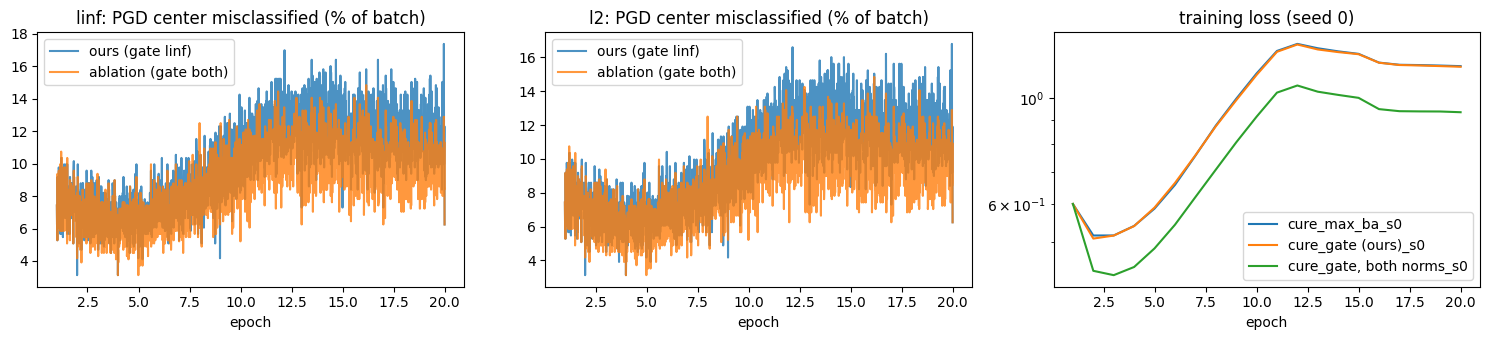

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for log, name in [(gate_log_main, "ours (gate linf)"), (gate_log_abl, "ablation (gate both)")]:
    a = np.array(log)
    n = len(a) // 2   # the log has 2 seeds; plot seed 0
    ax[0].plot(a[:n, 0], a[:n, 1], label=name, alpha=0.8)
    ax[1].plot(a[:n, 0], a[:n, 2], label=name, alpha=0.8)
ax[0].set_title("linf: PGD center misclassified (% of batch)"); ax[1].set_title("l2: PGD center misclassified (% of batch)")
for k in range(2):
    ax[k].set_xlabel("epoch"); ax[k].legend()
for k in [f"{best_b['name']}_s0", "cure_gate (ours)_s0", "cure_gate, both norms_s0"]:
    ax[2].plot(range(1, 21), losses[k], label=k)
ax[2].set_title("training loss (seed 0)"); ax[2].set_xlabel("epoch"); ax[2].set_yscale("log"); ax[2].legend()
plt.tight_layout(); plt.show()

with open("q2_results.json", "w") as f:
    json.dump({"results": results, "c": c_rows, "ablation": abl, "per_seed": per_seed, "losses": losses,
               "epoch_time": epoch_time, "times": times}, f, indent=1)


## (c)(iii) Results

Mean of seeds 0 and 1, A100 GPU. "controlled" = time of one epoch at full radius, median of 3 runs (`time_epoch`).

| method | clean | cert $\ell_\infty$ | cert $\ell_2$ | cert union | PGD $\ell_\infty$ | PGD $\ell_2$ | PGD union | gap $\ell_2$ | time/epoch (s) | controlled (s) |
|---|---|---|---|---|---|---|---|---|---|---|
| CURE-Max + BA (best of (b)) | 92.08 | 65.92 | 56.16 | 56.10 | 76.32 | 78.50 | 75.97 | 22.34 | 3.23 | 3.22 |
| CURE-Max + BA, 23 epochs (same time) | 92.04 | 65.79 | 56.07 | 56.00 | 76.38 | 78.42 | 75.98 | 22.35 | 3.27 | 3.22 |
| **CURE-Gate (ours)** | 92.01 | **66.34** | **56.74** | **56.65** | 77.22 | 78.94 | 76.66 | 22.20 | 3.47 | 3.63 |

Per seed, union certified: CURE-Max + BA 56.16 / 56.03, ours **57.06 / 56.24**. Our method uses 13% more time per epoch (one extra forward pass of the clean image and of each PGD center), so we also trained CURE-Max + BA for $\lceil 20 \cdot 1.127\rceil = 23$ epochs: it does not improve (56.00%).

## (c)(iv) Ablation: which norms are gated

| method | clean | cert $\ell_\infty$ | cert $\ell_2$ | cert union | PGD union | gap $\ell_2$ | final training loss (seed 0) |
|---|---|---|---|---|---|---|---|
| CURE-Max + BA | 92.08 | 65.92 | 56.16 | 56.10 | 75.97 | 22.34 | 1.166 |
| ours: gate $\ell_\infty$ only | 92.01 | 66.34 | 56.74 | **56.65** | 76.66 | 22.20 | 1.163 |
| ablation: gate both norms | **93.91** | 67.07 | 55.46 | 55.42 | **78.19** | 25.02 | 0.934 |

Per seed, union certified of the ablation: 56.05 / 54.78.

## (c)(v) Analysis

**Does it work?** Partly. Gating only $\ell_\infty$ increases the union certified accuracy by +0.55 points (56.10 → 56.65) at the same clean accuracy (92.01 vs 92.08), with the same gain in both seeds (+0.90 and +0.21), and it is better than CURE with the same training time (56.00). The gain is small, and with two seeds we cannot say it is larger than the noise with high confidence.

**Why it works (evidence).**
* The gain is in $\ell_2$, the norm that limits the union: certified $\ell_2$ +0.58 (56.16 → 56.74), and the union follows it (+0.55). Certified $\ell_\infty$ also increases (+0.42), so removing the impossible $\ell_\infty$ targets does not hurt the $\ell_\infty$ certificates of the other images.
* The training loss is almost the same as CURE-Max + BA (1.163 vs 1.166). This agrees with the mechanism: for a gated image the max of the two losses moves from the $\ell_\infty$ loss to the $\ell_2$ certified loss, so the total loss changes little, but the gradient of 6-12% of the batch (plot) goes to $\ell_2$.
* The $\ell_2$ gap gets a little smaller (22.20 vs 22.34): the extra certificates come from tighter bounds, not only from more empirical robustness.

**Why gating both norms is different (ablation).** If $\ell_2$ is gated too, the images that are hopeless for both norms are trained only with the clean loss. The training loss drops (0.934), the clean accuracy increases by +1.8 points (93.91) and the PGD union by +2.2 points, but the certified $\ell_2$ drops by 0.7 and the $\ell_2$ gap grows from 22.3 to 25.0 points. The freed capacity goes to clean and empirical robustness, not to certificates of the limiting norm. So the asymmetry is the important part of the method: gate the norm that does not limit the union, keep the certified loss of the norm that does. The ablation is still useful if clean accuracy matters more: +1.8 clean for −0.7 union.

**Why the gain is small.** The bottleneck is the looseness of the $\ell_2$ bounds: the gap is about 22 points for every method, and the $\ell_2$ network of (a) reaches only 57.8%. Gating changes *which* images get the $\ell_2$ loss, not how tight the $\ell_2$ bounds can be for this network, so it cannot remove most of the gap. Attempts to tighten the $\ell_2$ bounds directly did not work (next section).

## Process

1. Implemented and checked (a) and (b) first (also on the Mac CPU: the numbers were within 2 points of the GPU numbers; the GPU and CPU random streams differ).
2. Diagnosis: union $\approx$ certified $\ell_2$, and the $\ell_2$ gap is 2x the $\ell_\infty$ gap, so $\ell_2$ bounds are the bottleneck. On the trained networks, the verifier certifies almost all images with IBP; CROWN adds about 1% (measured on 2,000 test images).
3. Pilots (seed 0 unless noted, A100, union / clean). Same-GPU CURE-Max + BA reference: 56.16 / 91.83.

| pilot | idea | union | clean |
|---|---|---|---|
| verifier-aligned $\ell_2$ bound | $\ell_2$ loss on $\max(\text{IBP}, \text{CROWN})$, the verifier's bound (CROWN intermediate bounds without gradient) | 53.42 | 91.30 |
| CROWN-IBP $\ell_2$ bound [Zhang et al., ICLR 2020] | $\ell_2$ loss on $\max(\text{IBP}, \text{CROWN-IBP})$ | 55.51 | 92.63 |
| union logits | CE of the elementwise max $\max(\hat z^\infty, \hat z^2)$ | 56.14 | 91.66 |
| focus | extra $\ell_2$ loss on images certified for $\ell_\infty$ but not $\ell_2$ | 56.41 | 91.73 |
| ReLU stability [Xiao et al., ICLR 2019], weight 0.01 / 0.1 | regularizer on the $\ell_2$ ball | 56.01 / 51.26 | 89.51 / 83.75 |
| full $\ell_2$ ball ($\lambda_2 = 1$, diagnostic only) | IBP on the full $\ell_2$ ball | 56.26 | 85.22 |
| gate both, adversarial fallback (2 seeds) | CE at $x^*_p$ instead of clean CE | 54.82 | 93.58 |
| gate both, soft 0.5 (2 seeds) | average of clean and certified loss | 55.60 | 93.17 |
| **gate both, clean fallback (2 seeds)** | became the ablation | 55.42 | 93.91 |
| **gate $\ell_\infty$ only (2 seeds)** | final method | **56.65** | 92.01 |

The tighter bounds made the union *worse* (53.4% with the verifier's own CROWN bound). This agrees with "the paradox of certified training" [Jovanović et al., TMLR 2022]: tighter relaxations such as CROWN give less smooth losses and worse certified training than IBP. After these negative results we changed the direction from the bounds to *which images* get the certified loss, which led to the gating.

## References

* [GDS+19] Gowal et al. On the effectiveness of interval bound propagation for training verifiably robust models, 2019.
* [JCS24] Jiang, Cheung, Singh. Towards universal certified robustness with multi-norm training (CURE), 2024.
* Jiang and Singh. RAMP: Boosting adversarial robustness against multiple $l_p$ perturbations for universal robustness. NeurIPS 2024 (gradient projection, Eq. 4-7).
* Müller, Eckert, Fischer, Vechev. Certified training: Small boxes are all you need (SABR). ICLR 2023.
* Wang, Zou, Yi, Bailey, Ma, Gu. Improving adversarial robustness requires revisiting misclassified examples (MART). ICLR 2020.
* De Palma, Bunel, Dvijotham, Kumar, Stanforth, Lomuscio. Expressive losses for verified robustness via convex combinations. ICLR 2024.
* Jovanović, Balunović, Baader, Vechev. On the paradox of certified training. TMLR 2022.
* Zhang et al. Towards stable and efficient training of verifiably robust neural networks (CROWN-IBP). ICLR 2020.
* Xiao, Tjeng, Shafiullah, Madry. Training for faster adversarial robustness verification via inducing ReLU stability. ICLR 2019.
